In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.5 MB/s eta 0:00:00a 0:00:01


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="hl0e4YWkJZZilqeMCLkJ")
project = rf.workspace("weed-project-zbfhf").project("weed-detection-aiml-35-weed-and-crop")
version = project.version(3)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 41.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 125.0 MB/s eta 0:00:0000:01
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.21.0 requires google-cloud-bigquery-s


Extracting Dataset Version Zip to Weed-detection(AIML-35)-Weed-and-crop-3 in yolov8:: 100%|██████████| 8308/8308 [00:01<00:00, 5144.99it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
!pip install ultralytics

In [13]:
import os
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from pathlib import Path
import random
import shutil
from tqdm.notebook import tqdm
# Import YOLO and Roboflow
from ultralytics import YOLO
from roboflow import Roboflow

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("✅ Libraries imported")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


✅ Libraries imported
PyTorch version: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.64 GB


In [14]:
print("\n" + "="*60)
print("STEP 1: DOWNLOADING DATASET FROM ROBOFLOW")
print("="*60)

# Initialize Roboflow with your API key
rf = Roboflow(api_key="hl0e4YWkJZZilqeMCLkJ")

# Access your project
project = rf.workspace("weed-project-zbfhf").project("weed-detection-aiml-35-weed-and-crop")
version = project.version(3)

# Download dataset in YOLOv8 format
dataset = version.download("yolov8")

print(f"\n✅ Dataset downloaded successfully!")
print(f"Dataset location: {dataset.location}")
print(f"Dataset version: {version.version}")


STEP 1: DOWNLOADING DATASET FROM ROBOFLOW
loading Roboflow workspace...
loading Roboflow project...

✅ Dataset downloaded successfully!
Dataset location: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3
Dataset version: 3



STEP 2: DATASET EXPLORATION AND ANALYSIS

📊 Dataset Configuration:
Number of classes (nc): 15
Class names: ['Alternanthera pungens', 'Arachius', 'Chenopodium', 'Crab Grass', 'Crop', 'Dry leaf', 'Euphorbia Prostata', 'Grass', 'Leptadenia reticulata', 'Mexican Poppy', 'Spermacoce hispida', 'broadleaf plantain', 'parthenium hysterophorous', 'phhyllanthus', 'ragweed']
Train path: ../train/images
Val path: ../valid/images

📈 Dataset Statistics:
Training images: 3579
Validation images: 316
Test images: 253
Total images: 4148


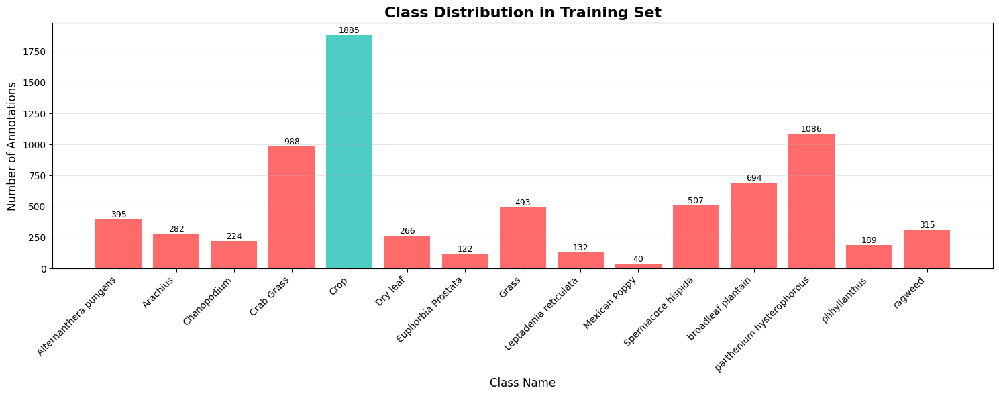

In [15]:
print("\n" + "="*60)
print("STEP 2: DATASET EXPLORATION AND ANALYSIS")
print("="*60)

# Load data.yaml
yaml_path = os.path.join(dataset.location, "data.yaml")
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

print(f"\n📊 Dataset Configuration:")
print(f"Number of classes (nc): {data['nc']}")
print(f"Class names: {data['names']}")
print(f"Train path: {data['train']}")
print(f"Val path: {data['val']}")

# Count images in each split
train_img_dir = os.path.join(dataset.location, 'train', 'images')
val_img_dir = os.path.join(dataset.location, 'valid', 'images')
test_img_dir = os.path.join(dataset.location, 'test', 'images')

train_count = len(os.listdir(train_img_dir)) if os.path.exists(train_img_dir) else 0
val_count = len(os.listdir(val_img_dir)) if os.path.exists(val_img_dir) else 0
test_count = len(os.listdir(test_img_dir)) if os.path.exists(test_img_dir) else 0

print(f"\n📈 Dataset Statistics:")
print(f"Training images: {train_count}")
print(f"Validation images: {val_count}")
print(f"Test images: {test_count}")
print(f"Total images: {train_count + val_count + test_count}")

# Calculate class distribution
class_counts = {name: 0 for name in data['names']}

# Count annotations in training set
label_dir = os.path.join(dataset.location, 'train', 'labels')
if os.path.exists(label_dir):
    for label_file in os.listdir(label_dir):
        with open(os.path.join(label_dir, label_file), 'r') as f:
            for line in f:
                class_id = int(line.strip().split()[0])
                class_counts[data['names'][class_id]] += 1

# Plot class distribution
plt.figure(figsize=(15, 6))
classes = list(class_counts.keys())
counts = list(class_counts.values())
colors = ['#FF6B6B' if 'weed' in c.lower() or c not in ['Crop'] else '#4ECDC4' for c in classes]

bars = plt.bar(classes, counts, color=colors)
plt.title('Class Distribution in Training Set', fontsize=16, fontweight='bold')
plt.xlabel('Class Name', fontsize=12)
plt.ylabel('Number of Annotations', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{count}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
print("\n" + "="*60)
print("STEP 1: DOWNLOADING DATASET FROM ROBOFLOW")
print("="*60)

# Initialize Roboflow with your API key
rf = Roboflow(api_key="hl0e4YWkJZZilqeMCLkJ")

# Access your project
project = rf.workspace("weed-project-zbfhf").project("weed-detection-aiml-35-weed-and-crop")
version = project.version(3)

# Download dataset in YOLOv8 format
dataset = version.download("yolov8")

print(f"\n✅ Dataset downloaded successfully!")
print(f"Dataset location: {dataset.location}")
print(f"Dataset version: {version.version}")


STEP 1: DOWNLOADING DATASET FROM ROBOFLOW
loading Roboflow workspace...
loading Roboflow project...

✅ Dataset downloaded successfully!
Dataset location: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3
Dataset version: 3



STEP 2: DATASET EXPLORATION AND ANALYSIS

📊 Dataset Configuration:
Number of classes (nc): 15
Class names: ['Alternanthera pungens', 'Arachius', 'Chenopodium', 'Crab Grass', 'Crop', 'Dry leaf', 'Euphorbia Prostata', 'Grass', 'Leptadenia reticulata', 'Mexican Poppy', 'Spermacoce hispida', 'broadleaf plantain', 'parthenium hysterophorous', 'phhyllanthus', 'ragweed']
Train path: ../train/images
Val path: ../valid/images

📈 Dataset Statistics:
Training images: 3579
Validation images: 316
Test images: 253
Total images: 4148


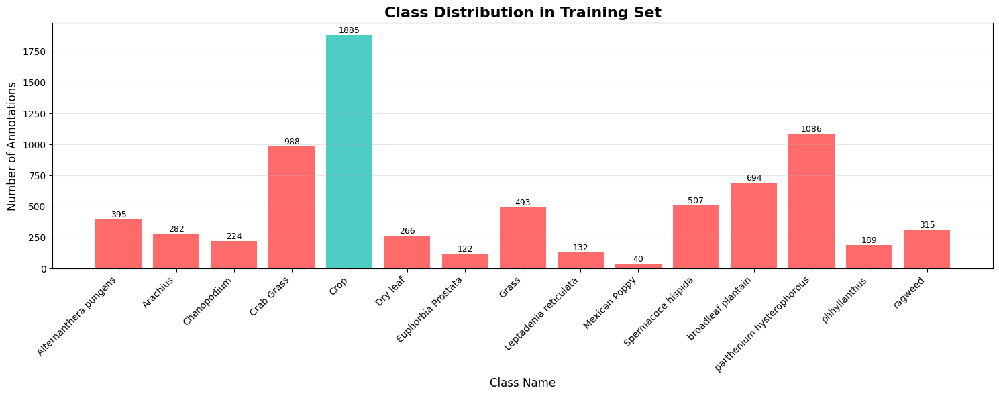

In [17]:
print("\n" + "="*60)
print("STEP 2: DATASET EXPLORATION AND ANALYSIS")
print("="*60)

# Load data.yaml
yaml_path = os.path.join(dataset.location, "data.yaml")
with open(yaml_path, 'r') as f:
    data = yaml.safe_load(f)

print(f"\n📊 Dataset Configuration:")
print(f"Number of classes (nc): {data['nc']}")
print(f"Class names: {data['names']}")
print(f"Train path: {data['train']}")
print(f"Val path: {data['val']}")

# Count images in each split
train_img_dir = os.path.join(dataset.location, 'train', 'images')
val_img_dir = os.path.join(dataset.location, 'valid', 'images')
test_img_dir = os.path.join(dataset.location, 'test', 'images')

train_count = len(os.listdir(train_img_dir)) if os.path.exists(train_img_dir) else 0
val_count = len(os.listdir(val_img_dir)) if os.path.exists(val_img_dir) else 0
test_count = len(os.listdir(test_img_dir)) if os.path.exists(test_img_dir) else 0

print(f"\n📈 Dataset Statistics:")
print(f"Training images: {train_count}")
print(f"Validation images: {val_count}")
print(f"Test images: {test_count}")
print(f"Total images: {train_count + val_count + test_count}")

# Calculate class distribution
class_counts = {name: 0 for name in data['names']}

# Count annotations in training set
label_dir = os.path.join(dataset.location, 'train', 'labels')
if os.path.exists(label_dir):
    for label_file in os.listdir(label_dir):
        with open(os.path.join(label_dir, label_file), 'r') as f:
            for line in f:
                class_id = int(line.strip().split()[0])
                class_counts[data['names'][class_id]] += 1

# Plot class distribution
plt.figure(figsize=(15, 6))
classes = list(class_counts.keys())
counts = list(class_counts.values())
colors = ['#FF6B6B' if 'weed' in c.lower() or c not in ['Crop'] else '#4ECDC4' for c in classes]

bars = plt.bar(classes, counts, color=colors)
plt.title('Class Distribution in Training Set', fontsize=16, fontweight='bold')
plt.xlabel('Class Name', fontsize=12)
plt.ylabel('Number of Annotations', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{count}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()



STEP 3: VISUALIZING SAMPLE IMAGES


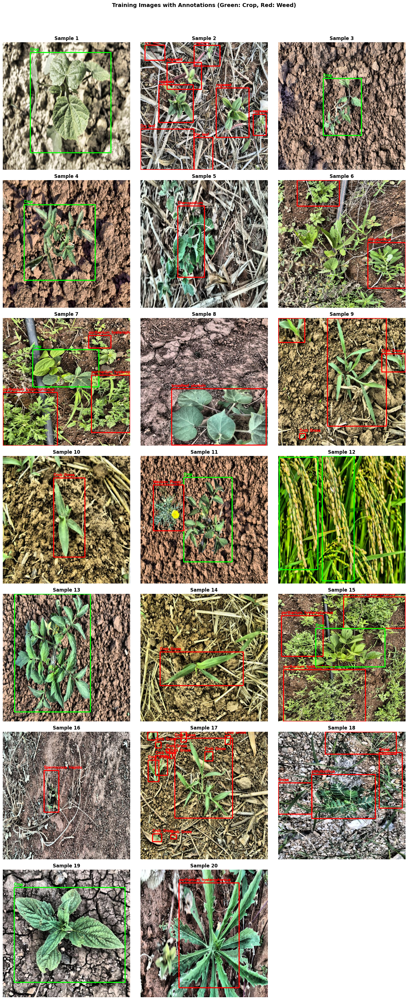

In [26]:
print("\n" + "="*60)
print("STEP 3: VISUALIZING SAMPLE IMAGES")
print("="*60)

def visualize_samples(dataset_path, num_samples=6):
    """Display sample images with their bounding box annotations"""
    
    # Get random training images
    img_dir = os.path.join(dataset_path, 'train', 'images')
    label_dir = os.path.join(dataset_path, 'train', 'labels')
    
    if not os.path.exists(img_dir):
        print("Training images directory not found!")
        return
    
    all_images = os.listdir(img_dir)
    sample_images = random.sample(all_images, min(num_samples, len(all_images)))
    
    # Calculate grid size
    cols = 3
    rows = (num_samples + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 5))
    axes = axes.flatten() if rows * cols > 1 else [axes]
    
    for idx, img_file in enumerate(sample_images):
        if idx >= num_samples:
            break
            
        # Read image
        img_path = os.path.join(img_dir, img_file)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # Read corresponding label file
        label_file = img_file.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')
        label_path = os.path.join(label_dir, label_file)
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                labels = f.readlines()
            
            # Draw bounding boxes
            for label in labels:
                parts = label.strip().split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    x_center = float(parts[1])
                    y_center = float(parts[2])
                    width = float(parts[3])
                    height = float(parts[4])
                    
                    # Convert to pixel coordinates
                    x1 = int((x_center - width/2) * w)
                    y1 = int((y_center - height/2) * h)
                    x2 = int((x_center + width/2) * w)
                    y2 = int((y_center + height/2) * h)
                    
                    # Determine color (green for crop, red for weed)
                    class_name = data['names'][class_id].lower()
                    color = (0, 255, 0) if 'crop' in class_name else (255, 0, 0)
                    
                    # Draw rectangle and label
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
                    cv2.putText(img, f"{data['names'][class_id]}", 
                              (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        
        axes[idx].imshow(img)
        axes[idx].set_title(f"Sample {idx+1}", fontsize=12, fontweight='bold')
        axes[idx].axis('off')
    
    # Hide empty subplots
    for idx in range(len(sample_images), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Training Images with Annotations (Green: Crop, Red: Weed)', 
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('sample_annotations.png', dpi=150, bbox_inches='tight')
    plt.show()

visualize_samples(dataset.location, num_samples=20)

In [25]:
print("\n" + "="*60)
print("STEP 4: CONFIGURING TRAINING PARAMETERS")
print("="*60)

# Model selection
MODEL_SIZES = {'large': 'yolov8l.pt'}

# Choose model size based on available GPU memory
if torch.cuda.is_available():
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9  # in GB
    if gpu_memory > 10:
        model_size = 'large'
    elif gpu_memory > 8:
        model_size = 'medium'
    else:
        model_size = 'small'
else:
    model_size = 'nano'

print(f"\n📌 Selected model: YOLOv8 {model_size.upper()}")
print(f"Model file: {MODEL_SIZES[model_size]}")

# Training configuration
config = {
    'model': MODEL_SIZES[model_size],
    'data': yaml_path,
    'epochs': 100,  # You can increase to 150-200 for better accuracy
    'imgsz': 640,
    'batch': 16,  # Reduce if you get out-of-memory errors
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'workers': 4,
    'patience': 20,  # Early stopping
    'save': True,
    'save_period': 10,  # Save checkpoint every 10 epochs
    'project': 'weed_detection_kaggle',
    'name': f'yolov8_{model_size}_weed_detector',
    'exist_ok': True,
    'pretrained': True,
    'optimizer': 'AdamW',
    'lr0': 0.001,  # Initial learning rate
    'lrf': 0.01,  # Final learning rate factor
    'momentum': 0.937,
    'weight_decay': 0.0005,
    'warmup_epochs': 3,
    'warmup_momentum': 0.8,
    'warmup_bias_lr': 0.1,
    'box': 7.5,  # Box loss gain
    'cls': 0.5,  # Class loss gain
    'dfl': 1.5,  # DFL loss gain
    'hsv_h': 0.015,  # HSV-Hue augmentation
    'hsv_s': 0.7,  # HSV-Saturation augmentation
    'hsv_v': 0.4,  # HSV-Value augmentation
    'degrees': 10.0,  # Rotation augmentation
    'translate': 0.1,  # Translation augmentation
    'scale': 0.5,  # Scaling augmentation
    'shear': 2.0,  # Shear augmentation
    'perspective': 0.0005,  # Perspective augmentation
    'flipud': 0.1,  # Flip up-down
    'fliplr': 0.5,  # Flip left-right
    'mosaic': 1.0,  # Mosaic augmentation
    'mixup': 0.2,  # Mixup augmentation
    'copy_paste': 0.2,  # Copy-paste augmentation
    'seed': 42
}

print("\n📋 Training Configuration:")
for key, value in config.items():
    print(f"  {key}: {value}")



STEP 4: CONFIGURING TRAINING PARAMETERS

📌 Selected model: YOLOv8 LARGE
Model file: yolov8l.pt

📋 Training Configuration:
  model: yolov8l.pt
  data: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3/data.yaml
  epochs: 100
  imgsz: 640
  batch: 16
  device: cuda
  workers: 4
  patience: 20
  save: True
  save_period: 10
  project: weed_detection_kaggle
  name: yolov8_large_weed_detector
  exist_ok: True
  pretrained: True
  optimizer: AdamW
  lr0: 0.001
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  warmup_epochs: 3
  warmup_momentum: 0.8
  warmup_bias_lr: 0.1
  box: 7.5
  cls: 0.5
  dfl: 1.5
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 10.0
  translate: 0.1
  scale: 0.5
  shear: 2.0
  perspective: 0.0005
  flipud: 0.1
  fliplr: 0.5
  mosaic: 1.0
  mixup: 0.2
  copy_paste: 0.2
  seed: 42


> deepseek code
> 

✅ Required packages installed
✅ Libraries imported
PyTorch version: 2.9.0+cu126
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.64 GB

STEP 1: DOWNLOADING DATASET FROM ROBOFLOW
loading Roboflow workspace...
loading Roboflow project...

✅ Dataset downloaded successfully!
Dataset location: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3
Dataset path for config: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3

STEP 2: VERIFYING DATASET STRUCTURE
✅ Found data.yaml at: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3/data.yaml

📊 Dataset Configuration:
  Number of classes (nc): 15
  Class names: ['Alternanthera pungens', 'Arachius', 'Chenopodium', 'Crab Grass', 'Crop', 'Dry leaf', 'Euphorbia Prostata', 'Grass', 'Leptadenia reticulata', 'Mexican Poppy', 'Spermacoce hispida', 'broadleaf plantain', 'parthenium hysterophorous', 'phhyllanthus', 'ragweed']
  Train path: ../train/images
  Val path: ../valid/images

📈 Dataset Statistics:
  Training images: 3579
  Validation

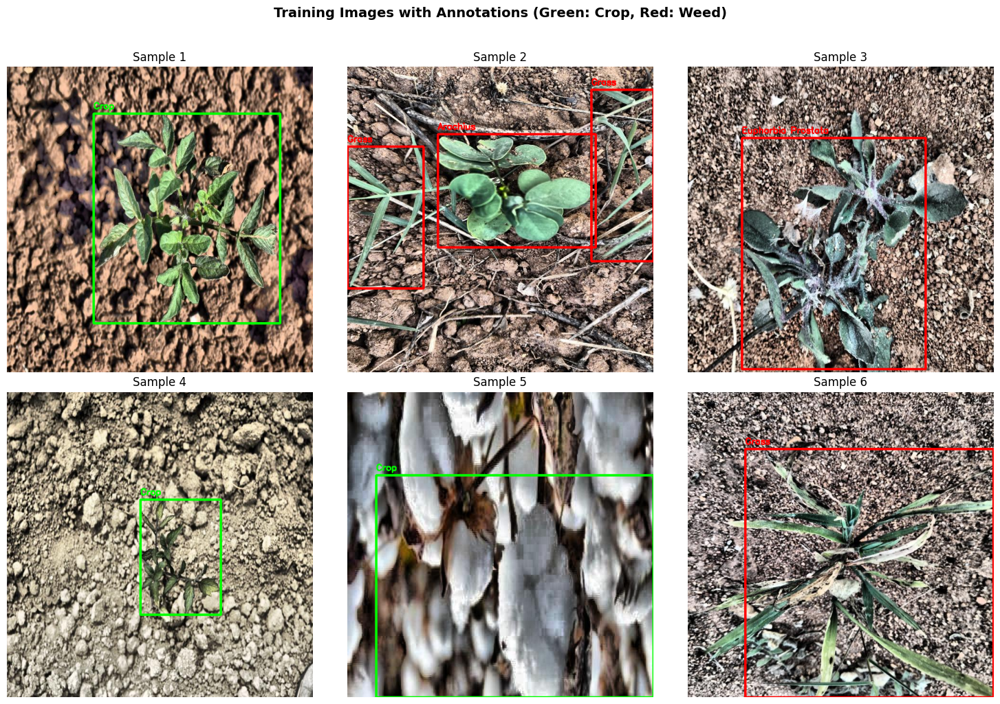


STEP 4: LOADING YOLOv8 LARGE MODEL WITH YOUR CONFIGURATION

📋 Your Training Configuration:
  model: yolov8l.pt
  data: /kaggle/working/Weed-detection(AIML-35)-Weed-and-crop-3/data.yaml
  epochs: 100
  imgsz: 640
  batch: 16
  device: cuda
  workers: 4
  patience: 20
  save: True
  save_period: 10
  project: weed_detection_kaggle
  name: yolov8_large_weed_detector
  exist_ok: True
  pretrained: True
  optimizer: AdamW
  lr0: 0.001
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  warmup_epochs: 3
  warmup_momentum: 0.8
  warmup_bias_lr: 0.1
  box: 7.5
  cls: 0.5
  dfl: 1.5
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 10.0
  translate: 0.1
  scale: 0.5
  shear: 2.0
  perspective: 0.0005
  flipud: 0.1
  fliplr: 0.5
  mosaic: 1.0
  mixup: 0.2
  copy_paste: 0.2
  seed: 42

📥 Downloading YOLOv8l pretrained model...
✅ Model downloaded

STEP 5: TRAINING YOLOv8 LARGE MODEL
⏳ Training started with YOLOv8l... This will take several hours
   Training progress will be shown below:

Ult

FileNotFoundError: [Errno 2] No such file or directory: 'weed_detection_kaggle/yolov8_large_weed_detector/weights/best.pt'

In [27]:
# -*- coding: utf-8 -*-
"""Weed Detection YOLOv8 Large Model - Kaggle Notebook

Automatically generated for weed and crop detection using YOLOv8l
"""

# ============================================
# CELL 1: Install Required Packages
# ============================================

!pip install -q ultralytics roboflow opencv-python matplotlib seaborn pandas tqdm
!pip install -q ensemble-boxes

print("✅ Required packages installed")

# ============================================
# CELL 2: Import Libraries
# ============================================

import os
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from pathlib import Path
import random
import shutil
import zipfile
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

from ultralytics import YOLO
from roboflow import Roboflow

# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(42)

print("✅ Libraries imported")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# ============================================
# CELL 3: Download Dataset from Roboflow
# ============================================

print("\n" + "="*70)
print("STEP 1: DOWNLOADING DATASET FROM ROBOFLOW")
print("="*70)

# Initialize Roboflow with your API key
rf = Roboflow(api_key="hl0e4YWkJZZilqeMCLkJ")

# Access your project
project = rf.workspace("weed-project-zbfhf").project("weed-detection-aiml-35-weed-and-crop")
version = project.version(3)

# Download dataset in YOLOv8 format
dataset = version.download("yolov8")

print(f"\n✅ Dataset downloaded successfully!")
print(f"Dataset location: {dataset.location}")

# Note the exact path for your configuration
dataset_path = dataset.location
print(f"Dataset path for config: {dataset_path}")

# ============================================
# CELL 4: Verify Dataset Structure
# ============================================

print("\n" + "="*70)
print("STEP 2: VERIFYING DATASET STRUCTURE")
print("="*70)

# Check if data.yaml exists at the expected location
yaml_path = os.path.join(dataset_path, "data.yaml")
if os.path.exists(yaml_path):
    print(f"✅ Found data.yaml at: {yaml_path}")
    
    # Load and display contents
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    
    print(f"\n📊 Dataset Configuration:")
    print(f"  Number of classes (nc): {data['nc']}")
    print(f"  Class names: {data['names']}")
    print(f"  Train path: {data['train']}")
    print(f"  Val path: {data['val']}")
    
    # Count images
    train_img_dir = os.path.join(dataset_path, 'train', 'images')
    val_img_dir = os.path.join(dataset_path, 'valid', 'images')
    test_img_dir = os.path.join(dataset_path, 'test', 'images')
    
    train_count = len(os.listdir(train_img_dir)) if os.path.exists(train_img_dir) else 0
    val_count = len(os.listdir(val_img_dir)) if os.path.exists(val_img_dir) else 0
    test_count = len(os.listdir(test_img_dir)) if os.path.exists(test_img_dir) else 0
    
    print(f"\n📈 Dataset Statistics:")
    print(f"  Training images: {train_count}")
    print(f"  Validation images: {val_count}")
    print(f"  Test images: {test_count}")
    print(f"  Total images: {train_count + val_count + test_count}")
else:
    print(f"❌ data.yaml not found at {yaml_path}")
    # Search for data.yaml
    for root, dirs, files in os.walk(dataset_path):
        if 'data.yaml' in files:
            yaml_path = os.path.join(root, 'data.yaml')
            print(f"✅ Found data.yaml at: {yaml_path}")
            break

# ============================================
# CELL 5: Visualize Sample Images
# ============================================

print("\n" + "="*70)
print("STEP 3: VISUALIZING SAMPLE IMAGES")
print("="*70)

def visualize_samples(dataset_path, num_samples=6):
    """Display sample images with bounding boxes"""
    
    img_dir = os.path.join(dataset_path, 'train', 'images')
    label_dir = os.path.join(dataset_path, 'train', 'labels')
    
    if not os.path.exists(img_dir):
        print("Training images directory not found!")
        return
    
    all_images = os.listdir(img_dir)
    sample_images = random.sample(all_images, min(num_samples, len(all_images)))
    
    cols = 3
    rows = (num_samples + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 5))
    axes = axes.flatten() if rows * cols > 1 else [axes]
    
    # Load class names from data.yaml
    with open(os.path.join(dataset_path, 'data.yaml'), 'r') as f:
        class_names = yaml.safe_load(f)['names']
    
    for idx, img_file in enumerate(sample_images):
        if idx >= num_samples:
            break
            
        # Read image
        img_path = os.path.join(img_dir, img_file)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # Read corresponding label
        label_file = img_file.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt')
        label_path = os.path.join(label_dir, label_file)
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                labels = f.readlines()
            
            for label in labels:
                parts = label.strip().split()
                if len(parts) >= 5:
                    class_id = int(parts[0])
                    x_center = float(parts[1])
                    y_center = float(parts[2])
                    width = float(parts[3])
                    height = float(parts[4])
                    
                    x1 = int((x_center - width/2) * w)
                    y1 = int((y_center - height/2) * h)
                    x2 = int((x_center + width/2) * w)
                    y2 = int((y_center + height/2) * h)
                    
                    # Color coding: Green for crop, Red for weeds
                    class_name = class_names[class_id].lower()
                    color = (0, 255, 0) if 'crop' in class_name else (255, 0, 0)
                    
                    cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
                    cv2.putText(img, class_names[class_id], 
                              (x1, y1-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        
        axes[idx].imshow(img)
        axes[idx].set_title(f"Sample {idx+1}", fontsize=12)
        axes[idx].axis('off')
    
    # Hide empty subplots
    for idx in range(len(sample_images), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Training Images with Annotations (Green: Crop, Red: Weed)', 
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('sample_annotations.png', dpi=150, bbox_inches='tight')
    plt.show()

visualize_samples(dataset_path, num_samples=6)

# ============================================
# CELL 6: YOUR SPECIFIC MODEL CONFIGURATION
# ============================================

print("\n" + "="*70)
print("STEP 4: LOADING YOLOv8 LARGE MODEL WITH YOUR CONFIGURATION")
print("="*70)

# Your exact configuration
config = {
    'model': 'yolov8l.pt',  # YOLOv8 Large model
    'data': yaml_path,
    'epochs': 100,
    'imgsz': 640,
    'batch': 16,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'workers': 4,
    'patience': 20,
    'save': True,
    'save_period': 10,
    'project': 'weed_detection_kaggle',
    'name': 'yolov8_large_weed_detector',
    'exist_ok': True,
    'pretrained': True,
    'optimizer': 'AdamW',
    'lr0': 0.001,
    'lrf': 0.01,
    'momentum': 0.937,
    'weight_decay': 0.0005,
    'warmup_epochs': 3,
    'warmup_momentum': 0.8,
    'warmup_bias_lr': 0.1,
    'box': 7.5,
    'cls': 0.5,
    'dfl': 1.5,
    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'degrees': 10.0,
    'translate': 0.1,
    'scale': 0.5,
    'shear': 2.0,
    'perspective': 0.0005,
    'flipud': 0.1,
    'fliplr': 0.5,
    'mosaic': 1.0,
    'mixup': 0.2,
    'copy_paste': 0.2,
    'seed': 42
}

print("\n📋 Your Training Configuration:")
print("="*50)
for key, value in config.items():
    print(f"  {key}: {value}")
print("="*50)

# Check if YOLOv8l model exists
if not os.path.exists('yolov8l.pt'):
    print("\n📥 Downloading YOLOv8l pretrained model...")
    model = YOLO('yolov8l.pt')  # This will download automatically
    print("✅ Model downloaded")
else:
    print("\n✅ YOLOv8l model already exists")

# ============================================
# CELL 7: TRAIN YOLOv8 LARGE MODEL
# ============================================

print("\n" + "="*70)
print("STEP 5: TRAINING YOLOv8 LARGE MODEL")
print("="*70)
print("⏳ Training started with YOLOv8l... This will take several hours")
print("   Training progress will be shown below:\n")

# Load the model
model = YOLO(config['model'])

# Train with your configuration
results = model.train(**config)

print("\n✅ Training completed successfully!")

# ============================================
# CELL 8: EVALUATE MODEL PERFORMANCE
# ============================================

print("\n" + "="*70)
print("STEP 6: EVALUATING MODEL PERFORMANCE")
print("="*70)

# Load the best model
best_model_path = f"{config['project']}/{config['name']}/weights/best.pt"
model = YOLO(best_model_path)

# Validate
metrics = model.val(data=yaml_path)

print("\n📊 Overall Validation Metrics:")
print(f"  mAP50: {metrics.box.map50:.4f}")
print(f"  mAP50-95: {metrics.box.map:.4f}")
print(f"  Precision: {metrics.box.mp:.4f}")
print(f"  Recall: {metrics.box.mr:.4f}")
print(f"  F1-Score: {2 * (metrics.box.mp * metrics.box.mr) / (metrics.box.mp + metrics.box.mr + 1e-16):.4f}")

print("\n📈 Per-Class Performance:")
print("-" * 50)
print(f"{'Class':<25} {'mAP50':<10} {'Precision':<12} {'Recall':<10}")
print("-" * 50)
for i, class_name in model.names.items():
    if i < len(metrics.box.ap50):
        print(f"{class_name:<25} {metrics.box.ap50[i]:<10.4f} {metrics.box.p[i]:<12.4f} {metrics.box.r[i]:<10.4f}")

# ============================================
# CELL 9: PLOT TRAINING RESULTS
# ============================================

print("\n" + "="*70)
print("STEP 7: PLOTTING TRAINING RESULTS")
print("="*70)

def plot_training_results(results_dir):
    """Plot training metrics from results.csv"""
    results_csv = os.path.join(results_dir, 'results.csv')
    
    if os.path.exists(results_csv):
        df = pd.read_csv(results_csv)
        
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle('YOLOv8 Large Model Training Results', fontsize=16, fontweight='bold')
        
        # Training losses
        axes[0, 0].plot(df['epoch'], df['train/box_loss'], label='Box Loss', color='blue')
        axes[0, 0].plot(df['epoch'], df['train/cls_loss'], label='Class Loss', color='orange')
        axes[0, 0].plot(df['epoch'], df['train/dfl_loss'], label='DFL Loss', color='green')
        axes[0, 0].set_title('Training Losses')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].legend()
        axes[0, 0].grid(True, alpha=0.3)
        
        # Validation losses
        axes[0, 1].plot(df['epoch'], df['val/box_loss'], label='Box Loss', color='blue')
        axes[0, 1].plot(df['epoch'], df['val/cls_loss'], label='Class Loss', color='orange')
        axes[0, 1].plot(df['epoch'], df['val/dfl_loss'], label='DFL Loss', color='green')
        axes[0, 1].set_title('Validation Losses')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Loss')
        axes[0, 1].legend()
        axes[0, 1].grid(True, alpha=0.3)
        
        # mAP metrics
        axes[0, 2].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50', color='purple', linewidth=2)
        axes[0, 2].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95', color='brown', linewidth=2)
        axes[0, 2].set_title('mAP Metrics')
        axes[0, 2].set_xlabel('Epoch')
        axes[0, 2].set_ylabel('mAP')
        axes[0, 2].legend()
        axes[0, 2].grid(True, alpha=0.3)
        
        # Precision and recall
        axes[1, 0].plot(df['epoch'], df['metrics/precision(B)'], label='Precision', color='green', linewidth=2)
        axes[1, 0].plot(df['epoch'], df['metrics/recall(B)'], label='Recall', color='red', linewidth=2)
        axes[1, 0].set_title('Precision & Recall')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Score')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
        
        # Learning rate
        axes[1, 1].plot(df['epoch'], df['lr/pg0'], label='LR pg0', color='cyan')
        axes[1, 1].plot(df['epoch'], df['lr/pg1'], label='LR pg1', color='magenta')
        axes[1, 1].plot(df['epoch'], df['lr/pg2'], label='LR pg2', color='yellow')
        axes[1, 1].set_title('Learning Rate')
        axes[1, 1].set_xlabel('Epoch')
        axes[1, 1].set_ylabel('Learning Rate')
        axes[1, 1].legend()
        axes[1, 1].grid(True, alpha=0.3)
        
        axes[1, 2].axis('off')
        
        plt.tight_layout()
        plt.savefig('training_results_large_model.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        print("✅ Training curves saved as 'training_results_large_model.png'")

plot_training_results(f"{config['project']}/{config['name']}")

# ============================================
# CELL 10: TEST ON SAMPLE VALIDATION IMAGES
# ============================================

print("\n" + "="*70)
print("STEP 8: TESTING ON SAMPLE VALIDATION IMAGES")
print("="*70)

def test_on_samples(model_path, dataset_path, num_samples=4):
    """Test model on validation images"""
    model = YOLO(model_path)
    
    val_img_dir = os.path.join(dataset_path, 'valid', 'images')
    
    if os.path.exists(val_img_dir):
        all_images = os.listdir(val_img_dir)
        test_images = random.sample(all_images, min(num_samples, len(all_images)))
        
        fig, axes = plt.subplots(2, 2, figsize=(15, 15))
        axes = axes.ravel()
        
        total_weeds = 0
        total_crops = 0
        
        for idx, img_file in enumerate(test_images):
            img_path = os.path.join(val_img_dir, img_file)
            
            # Run inference
            results = model(img_path, conf=0.25)[0]
            
            # Count detections
            weed_count = 0
            crop_count = 0
            for box in results.boxes:
                class_id = int(box.cls[0])
                class_name = model.names[class_id].lower()
                if 'crop' in class_name:
                    crop_count += 1
                else:
                    weed_count += 1
            
            total_weeds += weed_count
            total_crops += crop_count
            
            # Get annotated image
            annotated_img = results.plot()
            annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
            
            axes[idx].imshow(annotated_img)
            axes[idx].set_title(f"Image: {img_file[:20]}...\nWeeds: {weed_count} | Crops: {crop_count}", 
                              fontsize=11)
            axes[idx].axis('off')
        
        plt.suptitle(f'YOLOv8 Large Model Predictions\nTotal Weeds: {total_weeds}, Total Crops: {total_crops}', 
                    fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig('predictions_large_model.png', dpi=150, bbox_inches='tight')
        plt.show()
        
        print(f"✅ Sample predictions saved as 'predictions_large_model.png'")
        print(f"📊 Summary: Detected {total_weeds} weeds and {total_crops} crops across {num_samples} images")

test_on_samples(best_model_path, dataset_path, num_samples=4)

# ============================================
# CELL 11: CONFUSION MATRIX
# ============================================

print("\n" + "="*70)
print("STEP 9: CONFUSION MATRIX ANALYSIS")
print("="*70)

# Get confusion matrix
metrics = model.val(data=yaml_path, verbose=False)

if hasattr(metrics, 'confusion_matrix'):
    cm = metrics.confusion_matrix.matrix
    
    plt.figure(figsize=(16, 14))
    
    names = list(model.names.values()) + ['background']
    
    # Normalize
    cm_normalized = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-16)
    cm_normalized = np.nan_to_num(cm_normalized)
    
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=names, yticklabels=names, 
                cbar_kws={'label': 'Normalized Count'})
    plt.title('Normalized Confusion Matrix - YOLOv8 Large Model', fontsize=16, fontweight='bold')
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('Actual', fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(fontsize=9)
    plt.tight_layout()
    plt.savefig('confusion_matrix_large_model.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ Confusion matrix saved as 'confusion_matrix_large_model.png'")

# ============================================
# CELL 12: SAVE MODEL AND CREATE INFERENCE FUNCTION
# ============================================

print("\n" + "="*70)
print("STEP 10: SAVING MODEL AND CREATING INFERENCE FUNCTION")
print("="*70)

# Copy best model to working directory
shutil.copy(best_model_path, './best_weed_detector_yolov8l.pt')
print(f"✅ Model saved to: ./best_weed_detector_yolov8l.pt")

def detect_weeds(image_path, model_path='./best_weed_detector_yolov8l.pt', conf_threshold=0.25):
    """
    Detect weeds and crops in an image using YOLOv8 large model
    """
    model = YOLO(model_path)
    results = model(image_path, conf=conf_threshold)[0]
    
    detections = []
    weed_count = 0
    crop_count = 0
    
    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf[0])
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        
        detection = {
            'bbox': [x1, y1, x2, y2],
            'confidence': conf,
            'class_id': class_id,
            'class_name': class_name
        }
        detections.append(detection)
        
        if 'crop' in class_name.lower():
            crop_count += 1
        else:
            weed_count += 1
    
    annotated_img = results.plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    return {
        'detections': detections,
        'weed_count': weed_count,
        'crop_count': crop_count,
        'total_detections': len(detections),
        'annotated_image': annotated_img_rgb
    }

# Test the function
print("\n🧪 Testing inference function...")
val_img_dir = os.path.join(dataset_path, 'valid', 'images')
if os.path.exists(val_img_dir):
    test_img = os.path.join(val_img_dir, os.listdir(val_img_dir)[0])
    result = detect_weeds(test_img)
    
    print(f"\n📝 Test Results:")
    print(f"  Weeds detected: {result['weed_count']}")
    print(f"  Crops detected: {result['crop_count']}")
    print(f"  Total detections: {result['total_detections']}")

# ============================================
# CELL 13: GENERATE COMPREHENSIVE REPORT
# ============================================

print("\n" + "="*70)
print("STEP 11: GENERATING MODEL SUMMARY REPORT")
print("="*70)

def generate_report(model_path, dataset_path, config, output_file='model_summary_yolov8l.txt'):
    """Generate comprehensive model summary report"""
    
    model = YOLO(model_path)
    metrics = model.val(data=yaml_path, verbose=False)
    
    with open(output_file, 'w') as f:
        f.write("="*80 + "\n")
        f.write("WEED DETECTION MODEL - YOLOv8 LARGE TRAINING SUMMARY\n")
        f.write("="*80 + "\n\n")
        
        f.write("1. MODEL INFORMATION\n")
        f.write("-"*40 + "\n")
        f.write(f"Model: YOLOv8 Large (yolov8l.pt)\n")
        f.write(f"Model path: {model_path}\n")
        f.write(f"Number of classes: {len(model.names)}\n")
        f.write(f"Class names: {model.names}\n\n")
        
        f.write("2. DATASET INFORMATION\n")
        f.write("-"*40 + "\n")
        f.write(f"Dataset path: {dataset_path}\n")
        f.write(f"Training images: {len(os.listdir(os.path.join(dataset_path, 'train', 'images')))}")
        f.write(f"Validation images: {len(os.listdir(os.path.join(dataset_path, 'valid', 'images')))}")
        if os.path.exists(os.path.join(dataset_path, 'test', 'images')):
            f.write(f"Test images: {len(os.listdir(os.path.join(dataset_path, 'test', 'images')))}")
        f.write("\n\n")
        
        f.write("3. TRAINING CONFIGURATION\n")
        f.write("-"*40 + "\n")
        for key, value in config.items():
            f.write(f"{key}: {value}\n")
        f.write("\n")
        
        f.write("4. EVALUATION METRICS\n")
        f.write("-"*40 + "\n")
        f.write(f"mAP50: {metrics.box.map50:.4f}\n")
        f.write(f"mAP50-95: {metrics.box.map:.4f}\n")
        f.write(f"Precision: {metrics.box.mp:.4f}\n")
        f.write(f"Recall: {metrics.box.mr:.4f}\n")
        f.write(f"F1-Score: {2 * (metrics.box.mp * metrics.box.mr) / (metrics.box.mp + metrics.box.mr + 1e-16):.4f}\n\n")
        
        f.write("5. PER-CLASS PERFORMANCE\n")
        f.write("-"*40 + "\n")
        f.write(f"{'Class':<25} {'mAP50':<10} {'Precision':<12} {'Recall':<10}\n")
        f.write("-"*50 + "\n")
        for i, class_name in model.names.items():
            if i < len(metrics.box.ap50):
                f.write(f"{class_name:<25} {metrics.box.ap50[i]:<10.4f} {metrics.box.p[i]:<12.4f} {metrics.box.r[i]:<10.4f}\n")
    
    print(f"✅ Report saved to: {output_file}")
    
    # Display summary
    print("\n📋 Report Summary:")
    print(f"  Model: YOLOv8 Large")
    print(f"  mAP50: {metrics.box.map50:.4f}")
    print(f"  mAP50-95: {metrics.box.map:.4f}")
    print(f"  Precision: {metrics.box.mp:.4f}")
    print(f"  Recall: {metrics.box.mr:.4f}")

generate_report(best_model_path, dataset_path, config)

# ============================================
# CELL 14: CREATE ZIP FILE WITH ALL RESULTS
# ============================================

print("\n" + "="*70)
print("STEP 12: PACKAGING RESULTS FOR DOWNLOAD")
print("="*70)

files_to_zip = [
    'best_weed_detector_yolov8l.pt',
    'model_summary_yolov8l.txt',
    'training_results_large_model.png',
    'confusion_matrix_large_model.png',
    'predictions_large_model.png',
    'sample_annotations.png'
]

with zipfile.ZipFile('weed_detection_yolov8l_results.zip', 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"✅ Added {file}")

print("\n📦 Created 'weed_detection_yolov8l_results.zip' with all important files")

# ============================================
# CELL 15: FINAL SUMMARY
# ============================================

print("\n" + "="*80)
print("✅ YOLOv8 LARGE MODEL TRAINING COMPLETED SUCCESSFULLY!")
print("="*80)

print("\n📁 Generated Files:")
print("  • best_weed_detector_yolov8l.pt - Trained YOLOv8 large model weights")
print("  • model_summary_yolov8l.txt - Complete training summary report")
print("  • training_results_large_model.png - Training curves plot")
print("  • confusion_matrix_large_model.png - Confusion matrix")
print("  • predictions_large_model.png - Sample predictions on validation images")
print("  • sample_annotations.png - Sample training images with annotations")
print("  • weed_detection_yolov8l_results.zip - All files packaged for download")

print("\n📊 Final Model Performance:")
print(f"  mAP50: {metrics.box.map50:.4f}")
print(f"  mAP50-95: {metrics.box.map:.4f}")
print(f"  Precision: {metrics.box.mp:.4f}")
print(f"  Recall: {metrics.box.mr:.4f}")

print("\n🔍 How to use your trained model:")
print("""
from ultralytics import YOLO

# Load your trained model
model = YOLO('best_weed_detector_yolov8l.pt')

# Run inference on new images
results = model('path/to/your/image.jpg')

# Display results
results[0].show()

# Get detection information
for result in results:
    boxes = result.boxes
    for box in boxes:
        class_name = model.names[int(box.cls[0])]
        confidence = float(box.conf[0])
        print(f"Detected: {class_name} ({confidence:.2%})")
""")

print("\n" + "="*80)
print("🎉 You can now download 'weed_detection_yolov8l_results.zip' from Kaggle!")
print("="*80)

In [31]:



import os
import glob
import shutil
from IPython.display import FileLink, display

# Find the model
model_files = glob.glob('/kaggle/working/**/best.pt', recursive=True)

if model_files:
    model_path = model_files[0]
    print(f"✅ Found model at: {model_path}")
    
    # Copy to easy location
    shutil.copy(model_path, 'weed_model.pt')
    print(f"\n📦 Model copied to: weed_model.pt")
    print(f"   Size: {os.path.getsize('weed_model.pt') / 1024 / 1024:.2f} MB")
    
    # Create download link
    print("\n📥 Click to download:")
    display(FileLink('weed_model.pt'))
    
    # Also create a zip with everything
    import zipfile
    with zipfile.ZipFile('weed_model_complete.zip', 'w') as zipf:
        zipf.write('weed_model.pt', 'best_weed_detector_model.pt')
        # Add any PNG files
        for png in glob.glob('*.png'):
            zipf.write(png)
    
    print(f"\n📦 Complete package: weed_model_complete.zip")
    display(FileLink('weed_model_complete.zip'))
else:
    print("❌ Model not found. Searching...")
    for root, dirs, files in os.walk('/kaggle/working/'):
        if 'best.pt' in files:
            print(f"Found at: {os.path.join(root, 'best.pt')}")

✅ Found model at: /kaggle/working/runs/detect/weed_detection_kaggle/yolov8_large_weed_detector/weights/best.pt

📦 Model copied to: weed_model.pt
   Size: 83.61 MB

📥 Click to download:


/kaggle/working/weed_model.pt


📦 Complete package: weed_model_complete.zip


/kaggle/working/weed_model_complete.zip